# Baseline: n-gram next-move prediction
Count-based baselines for next-move prediction. Each position is one example. The target is the next move (UCI string, e.g. `e2e4`).

| Model | Prediction rule |
|---|---|
| global | the single most common move |
| per-ply | the most common move at this ply (move number) |
| last 1 / 2 / 3 moves | the most common next move after the same last 1, 2 or 3 moves, backing off to a shorter context when the longer one was never seen in training |
| last 3 + Elo | the same, but counted separately for each of seven Elo groups |

Split is by game (hash of the move list, so duplicate games stay together): 80% train, 10% validation, 10% test. Validation is reserved for the neural model. All numbers here are on the **test** split.

Not included: the legal-move mask. It needs `python-chess`, and it will be added when we compare against the neural model. Every baseline prediction is a move seen in training, so it can occasionally be illegal.

In [1]:
import time
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt

PATH = "dataset.parquet"
N_GAMES = 1_000_000      # approximate number of games to use (every k-th row group)
N_ELO_GROUPS = 7
K = 5                    # top-K predictions kept per context
PLY_CAP = 300            # per-ply table treats plies >= PLY_CAP as one bucket

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "axes.titlesize": 11,
})

## 1. Load a subset
Every k-th row group is read, so the subset spans all sources. Games with a missing Elo (either player) are dropped. Moves are converted to integer ids.

In [2]:
t0 = time.time()
pf = pq.ParquetFile(PATH)
total = pf.metadata.num_rows
step = max(1, int(total / N_GAMES))
vocab = {}
ids_l, lens_l, elo_l, hash_l, nmiss = [], [], [], [], 0

for i in range(0, pf.num_row_groups, step):
    t = pf.read_row_group(i, columns=["white_elo", "black_elo", "moves_uci"])
    mu = t["moves_uci"].combine_chunks()
    lens = pc.list_value_length(mu).to_numpy(zero_copy_only=False).astype(np.int64)
    w = t["white_elo"].to_pandas().to_numpy(dtype="float64", na_value=np.nan)
    b = t["black_elo"].to_pandas().to_numpy(dtype="float64", na_value=np.nan)
    ok = ~(np.isnan(w) | np.isnan(b))
    nmiss += int((~ok).sum())

    h = pd.util.hash_array(pc.binary_join(mu, " ").to_numpy(zero_copy_only=False))
    enc = pc.dictionary_encode(mu.flatten())
    mapping = np.array([vocab.setdefault(m, len(vocab)) for m in enc.dictionary.to_pylist()], dtype=np.int32)
    ids = mapping[enc.indices.to_numpy()]

    keep_pos = np.repeat(ok, lens)
    ids_l.append(ids[keep_pos]); lens_l.append(lens[ok])
    elo_l.append((w[ok] + b[ok]) / 2); hash_l.append(h[ok])

ids = np.concatenate(ids_l); lens = np.concatenate(lens_l)
mean_elo = np.concatenate(elo_l); ghash = np.concatenate(hash_l)
del ids_l, lens_l, elo_l, hash_l
V = len(vocab); B = V + 1; START = V
inv_vocab = np.array(sorted(vocab, key=vocab.get))
print(f"row groups read every {step}th; games kept {len(lens):,} (dropped {nmiss:,} with missing Elo)")
print(f"positions {len(ids):,}   distinct moves V = {V:,}   load time {time.time()-t0:.0f}s")

row groups read every 14th; games kept 867,995 (dropped 146,005 with missing Elo)
positions 73,896,525   distinct moves V = 1,954   load time 10s


## 2. Split and Elo groups

In [3]:
bucket = (ghash % 100).astype(int)
game_split = np.where(bucket < 80, 0, np.where(bucket < 90, 1, 2))      # 0 train, 1 val, 2 test
edges = np.quantile(mean_elo[game_split == 0], np.linspace(0, 1, N_ELO_GROUPS + 1)[1:-1])
game_group = np.searchsorted(edges, mean_elo, side="right")             # 0..N_ELO_GROUPS-1
print("Elo group edges (from train):", np.round(edges).astype(int))

starts = np.cumsum(lens) - lens
ply = np.arange(len(ids)) - np.repeat(starts, lens)
pos_split = np.repeat(game_split, lens)
pos_group = np.repeat(game_group, lens)

train_idx = np.flatnonzero(pos_split == 0)
test_idx = np.flatnonzero(pos_split == 2)
print(pd.DataFrame({"games": np.bincount(game_split), "positions": np.bincount(pos_split)},
                   index=["train", "val", "test"]).to_string())

Elo group edges (from train): [2068 2250 2386 2510 2598 2666]
        games  positions
train  694320   59126463
val     86794    7373776
test    86881    7396286


## 3. Context keys
A context is turned into one integer. Positions near the start of a game are padded with a `START` token, so the first moves of a game are modelled as well.

In [4]:
def shifted(k):
    out = np.empty_like(ids); out[:k] = START; out[k:] = ids[:-k]
    out[ply < k] = START
    return out

p1, p2, p3 = shifted(1), shifted(2), shifted(3)

def ctx_key(kind, idx):
    if kind == "global": return np.zeros(len(idx), np.int64)
    if kind == "ply":    return np.minimum(ply[idx], PLY_CAP - 1).astype(np.int64)
    a = p1[idx].astype(np.int64)
    if kind == "n1": return a
    a = a * B + p2[idx]
    if kind == "n2": return a
    return a * B + p3[idx]                                              # n3

def make_key(name, idx):
    kind, with_elo = (name[:-1], True) if name.endswith("E") else (name, False)
    key = ctx_key(kind, idx)
    return key * N_ELO_GROUPS + pos_group[idx] if with_elo else key

## 4. Count tables
For each context, count how often each next move follows it in the training positions, and keep the top K. Counting uses sorted integer arrays, so it stays compact at hundreds of millions of positions.

In [5]:
class Table:
    def __init__(self, key, tgt):
        pk = key * V + tgt.astype(np.int64)
        u, c = np.unique(pk, return_counts=True)
        k, t = u // V, (u % V).astype(np.int32)
        o = np.lexsort((-c, k)); k, t = k[o], t[o]
        self.uk, st = np.unique(k, return_index=True)
        cnt = np.diff(np.append(st, len(k)))
        rank = np.arange(len(k)) - np.repeat(st, cnt)
        sel = rank < K
        self.top = np.full((len(self.uk), K), -1, np.int32)
        self.top[np.repeat(np.arange(len(self.uk)), cnt)[sel], rank[sel]] = t[sel]

    def lookup(self, key):
        i = np.minimum(np.searchsorted(self.uk, key), len(self.uk) - 1)
        return self.uk[i] == key, self.top[i]

NAMES = ["global", "ply", "n1", "n2", "n3", "plyE", "n1E", "n2E", "n3E"]
tables = {}
for nm in NAMES:
    t0 = time.time()
    tables[nm] = Table(make_key(nm, train_idx), ids[train_idx])
    print(f"{nm:>7}: {len(tables[nm].uk):>12,} contexts   {time.time()-t0:.0f}s")

 global:            1 contexts   1s
    ply:          300 contexts   2s
     n1:        1,944 contexts   2s
     n2:    2,287,646 contexts   6s
     n3:   26,101,874 contexts   8s
   plyE:        2,100 contexts   3s
    n1E:       13,316 contexts   4s
    n2E:    8,749,570 contexts   8s
    n3E:   35,429,437 contexts   9s


## 5. Predict and evaluate
A model is a chain of tables. The first table that has seen the context makes the prediction, otherwise the next table is tried, and the last one (global) always answers.

Splitting by Elo divides the counts by about seven, so many Elo-specific contexts are never seen. The "mixed backoff" model tries the Elo-specific table first, then the all-Elo table for the same context length, before shortening the context.

In [6]:
CHAINS = {
    "global":              ["global"],
    "per-ply":             ["ply", "global"],
    "last 1 move":         ["n1", "ply", "global"],
    "last 2 moves":        ["n2", "n1", "ply", "global"],
    "last 3 moves":        ["n3", "n2", "n1", "ply", "global"],
    "last 3 moves + Elo":  ["n3E", "n2E", "n1E", "plyE", "ply", "global"],
    "last 3 + Elo (mixed backoff)": ["n3E", "n3", "n2E", "n2", "n1E", "n1", "plyE", "ply", "global"],
}

target = ids[test_idx]
def predict(chain):
    pred = np.full((len(test_idx), K), -1, np.int32)
    todo = np.ones(len(test_idx), bool)
    for nm in chain:
        hit, top = tables[nm].lookup(make_key(nm, test_idx))
        use = hit & todo
        pred[use] = top[use]; todo &= ~hit
    return pred

preds = {m: predict(c) for m, c in CHAINS.items()}
correct = {m: (p == target[:, None]) for m, p in preds.items()}      # n x K, True at the rank of the right move

res = pd.DataFrame({m: {f"top-{k}": c[:, :k].any(axis=1).mean() for k in (1, 3, 5)} for m, c in correct.items()}).T
print(f"test positions: {len(test_idx):,}")
print((res * 100).round(2).to_string())
res.to_csv("baseline_results.csv")

test positions: 7,396,286
                              top-1  top-3  top-5
global                         1.04   3.09   4.96
per-ply                        4.50  10.01  13.73
last 1 move                    8.05  16.39  21.06
last 2 moves                  17.17  30.02  36.17
last 3 moves                  19.04  30.58  35.24
last 3 moves + Elo            17.11  26.85  30.53
last 3 + Elo (mixed backoff)  17.34  26.63  29.87


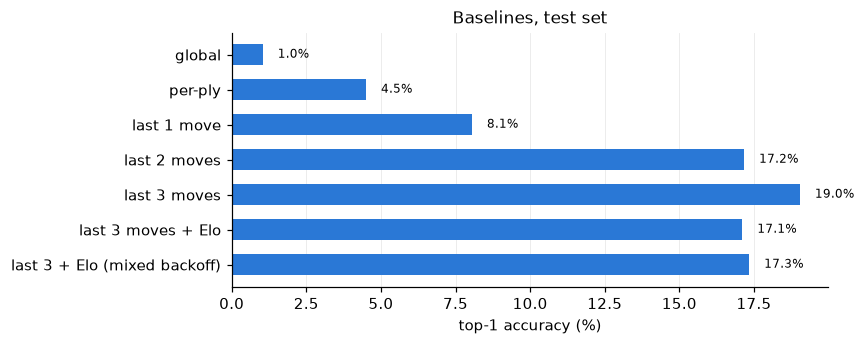

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
r = res["top-1"] * 100
ax.barh(r.index[::-1], r.values[::-1], color=BLUE, height=0.6)
for y, v in enumerate(r.values[::-1]): ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("top-1 accuracy (%)"); ax.set_title("Baselines, test set"); ax.grid(axis="y", visible=False)
plt.show()

## 6. Accuracy by ply and by Elo group

        per-ply  last 2 moves  last 3 moves  last 3 moves + Elo  last 3 + Elo (mixed backoff)
0-9        20.6          46.4          52.9                52.9                          53.0
10-19       8.7          28.4          37.3                35.1                          35.6
20-29       3.4          16.8          20.3                17.2                          17.7
30-39       1.5          11.0          11.3                 9.5                           9.5
40-59       1.0           8.2           7.8                 6.4                           6.3
60-79       1.0           8.6           7.9                 6.1                           6.2
80-119      0.9          11.1          10.1                 7.4                           7.9
120+        0.7          14.6          13.7                10.1                          11.1

positions per bin: {'0-9': 868810, '10-19': 866003, '20-29': 851502, '30-39': 822194, '40-59': 1458483, '60-79': 1069238, '80-119': 1056736, '120+': 4033

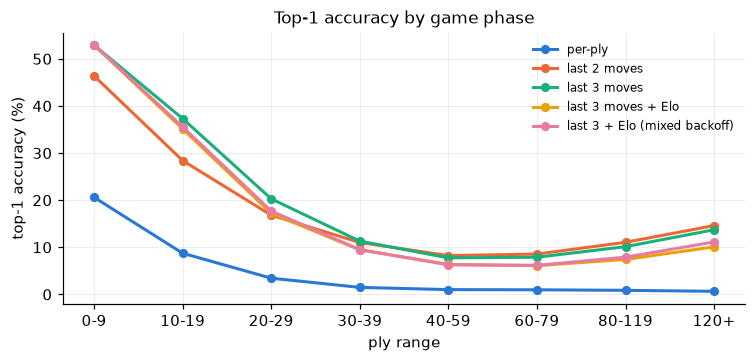

In [8]:
bins = [0, 10, 20, 30, 40, 60, 80, 120, 10_000]
labels = [f"{a}-{b-1}" if b < 10_000 else f"{a}+" for a, b in zip(bins[:-1], bins[1:])]
pb = pd.cut(ply[test_idx], bins, right=False, labels=labels)

show = ["per-ply", "last 2 moves", "last 3 moves", "last 3 moves + Elo", "last 3 + Elo (mixed backoff)"]
colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
by_ply = pd.DataFrame({m: pd.Series(correct[m][:, 0]).groupby(pb, observed=True).mean() for m in show}) * 100
print(by_ply.round(1).to_string())
print("\npositions per bin:", pd.Series(pb).value_counts().reindex(labels).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
for m, c in zip(show, colors): ax.plot(range(len(by_ply)), by_ply[m], color=c, lw=2, marker="o", ms=5, label=m)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_xlabel("ply range"); ax.set_ylabel("top-1 accuracy (%)"); ax.set_title("Top-1 accuracy by game phase")
ax.legend(frameon=False, fontsize=8); plt.show()

Elo group edges: [2068 2250 2386 2510 2598 2666]
         last 3 moves  last 3 moves + Elo  last 3 + Elo (mixed backoff)  gain (mixed)
group 0         17.97               16.26                         16.44         -1.53
group 1         18.72               16.69                         16.95         -1.77
group 2         19.19               17.08                         17.37         -1.82
group 3         19.20               17.05                         17.35         -1.85
group 4         18.90               16.73                         16.96         -1.93
group 5         18.79               16.75                         16.95         -1.85
group 6         20.27               18.90                         19.05         -1.22


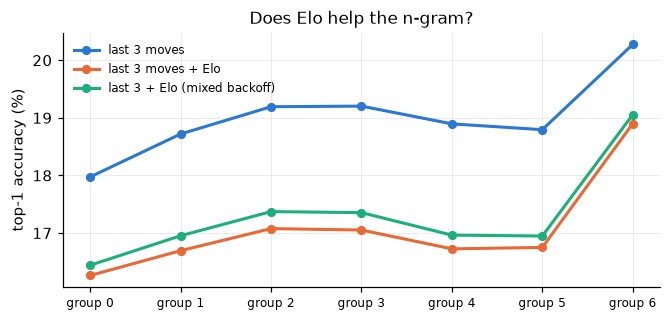

In [9]:
g_test = pos_group[test_idx]
by_g = pd.DataFrame({m: pd.Series(correct[m][:, 0]).groupby(g_test).mean() for m in ["last 3 moves", "last 3 moves + Elo", "last 3 + Elo (mixed backoff)"]}) * 100
by_g.index = [f"group {i}" for i in by_g.index]
by_g["gain (mixed)"] = by_g["last 3 + Elo (mixed backoff)"] - by_g["last 3 moves"]
print("Elo group edges:", np.round(edges).astype(int))
print(by_g.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 3))
for m, c in zip(["last 3 moves", "last 3 moves + Elo", "last 3 + Elo (mixed backoff)"], [BLUE, ORANGE, AQUA]):
    ax.plot(range(len(by_g)), by_g[m], color=c, lw=2, marker="o", ms=5, label=m)
ax.set_xticks(range(len(by_g))); ax.set_xticklabels(by_g.index, fontsize=8)
ax.set_ylabel("top-1 accuracy (%)"); ax.set_title("Does Elo help the n-gram?")
ax.legend(frameon=False, fontsize=8); plt.show()

## 7. How often does the longest context apply?

In [10]:
hit3, _ = tables["n3"].lookup(make_key("n3", test_idx))
hit2, _ = tables["n2"].lookup(make_key("n2", test_idx))
hit1, _ = tables["n1"].lookup(make_key("n1", test_idx))
print(f"test positions whose last-3-move context was seen in training: {hit3.mean():.1%}")
print(f"... last-2: {hit2.mean():.1%}   last-1: {hit1.mean():.1%}")
pb_hit = pd.Series(hit3).groupby(pb, observed=True).mean() * 100
print("\nlast-3 context seen in training, by ply range (%):"); print(pb_hit.round(1).to_string())

test positions whose last-3-move context was seen in training: 64.5%
... last-2: 99.2%   last-1: 100.0%

last-3 context seen in training, by ply range (%):
0-9       99.9
10-19     97.9
20-29     86.6
30-39     67.3
40-59     48.3
60-79     40.1
80-119    41.8
120+      47.0


## 8. Examples

In [11]:
rng = np.random.default_rng(0)
m = "last 3 + Elo (mixed backoff)"
for j in rng.choice(len(test_idx), 8, replace=False):
    pos = test_idx[j]
    hist = " ".join(str(x) for x in inv_vocab[ids[max(pos - ply[pos], pos - 6):pos]])
    top = [str(inv_vocab[x]) for x in preds[m][j] if x >= 0]
    print(f"ply {ply[pos]:>3} | ...{hist:<30} | actual {str(inv_vocab[ids[pos]])} | top-5 {top}")

ply  13 | ...d8d7 e1g1 g8f6 d2d4 f6e4 d1e2  | actual d6d5 | top-5 ['e4d6']
ply  24 | ...e1g1 c5d4 a4b5 a6b5 a1a8 b7a8  | actual d1d4 | top-5 ['c3b5', 'b1c3', 'b2b3', 'b1a3', 'b3c4']
ply  94 | ...f4f5 c8b6 f5f6 e7f8 f6g7 f8g7  | actual g4e5 | top-5 ['d2g5', 'e5d6', 'f3f4', 'g4g5', 'e4c5']
ply  44 | ...g3e1 g4f3 g2f3 g8h8 c3d5 e8f8  | actual h1f1 | top-5 ['e3b6', 'g1f3', 'e1g1', 'a1b1', 'f1e2']
ply  49 | ...f8c8 c3c4 c7a5 b2b3 a5b4 f4f5  | actual a7a5 | top-5 ['e6d7', 'b4b3', 'g6f5', 'd4b3', 'f7f6']
ply   1 | ...d2d4                           | actual g8f6 | top-5 ['g8f6', 'd7d5', 'e7e6', 'g7g6', 'd7d6']
ply  30 | ...h3f2 a6c5 a1b1 a5c7 e1g1 c5a4  | actual c3b5 | top-5 ['c3a4', 'c3d1', 'c3e4', 'c3e5', 'g5e4']
ply  61 | ...f8e8 c1c6 e5b2 f1d1 a8d8 d1d2  | actual b2c3 | top-5 ['d8d2', 'd8d7', 'h7h6', 'f8e8', 'h6e3']
